<a href="https://colab.research.google.com/github/probml/pyprobml/blob/master/notebooks/iris_dtree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision tree classifier on Iris data

Based on 
https://github.com/ageron/handson-ml2/blob/master/06_decision_trees.ipynb

In [1]:
# Python ≥3.5 is required
import sys

assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn

assert sklearn.__version__ >= "0.20"

# Common imports
import numpy as np
import os
import pandas as pd

from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
import seaborn as sns


# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
# Font sizes
SIZE_SMALL = 18  # 14
SIZE_MEDIUM = 20  # 18
SIZE_LARGE = 24

# https://stackoverflow.com/a/39566040
plt.rc("font", size=SIZE_SMALL)  # controls default text sizes
plt.rc("axes", titlesize=SIZE_SMALL)  # fontsize of the axes title
plt.rc("axes", labelsize=SIZE_SMALL)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SIZE_SMALL)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SIZE_SMALL)  # fontsize of the tick labels
plt.rc("legend", fontsize=SIZE_SMALL)  # legend fontsize
plt.rc("figure", titlesize=SIZE_LARGE)  # fontsize of the figure title

# Data

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


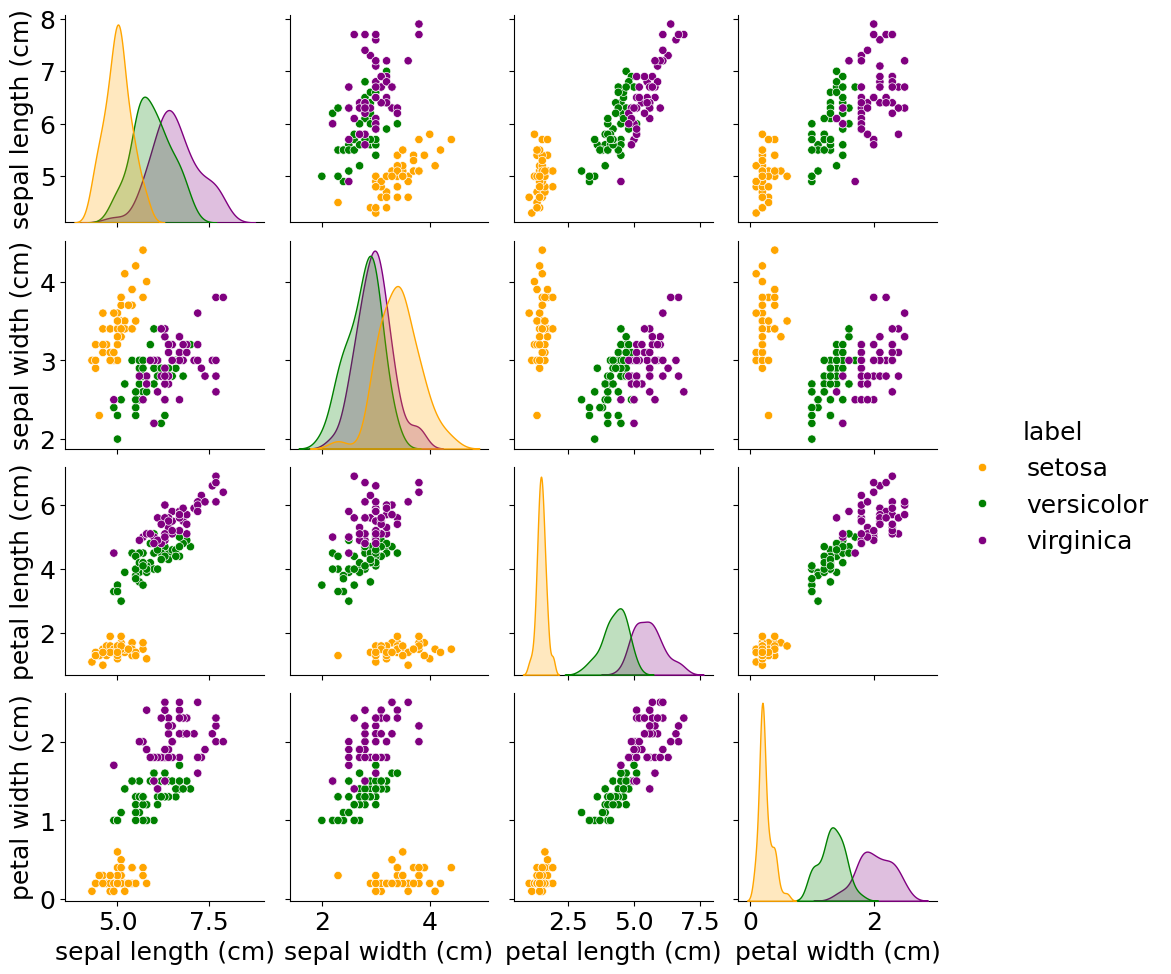

In [17]:
iris = load_iris()
X = iris.data
y = iris.target
print(iris.feature_names)

# Convert to pandas dataframe
df = pd.DataFrame(data=X, columns=iris.feature_names)
df["label"] = pd.Series(iris.target_names[y], dtype="category")

# we pick a color map to match that used by decision tree graphviz
# cmap = ListedColormap(['#fafab0','#a0faa0', '#9898ff']) # orange, green, blue/purple
# cmap = ListedColormap(['orange', 'green', 'purple'])
palette = {"setosa": "orange", "versicolor": "green", "virginica": "purple"}

g = sns.pairplot(df, vars=df.columns[0:4], hue="label", palette=palette)
# g = sns.pairplot(df, vars = df.columns[0:4], hue="label")
plt.savefig("iris_scatterplot_v2.pdf")
plt.show()

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris

iris = load_iris()
print(iris.target_names)
print(iris.feature_names)

# ndx = [0, 2] # sepal length, petal length
ndx = [2, 3]  # petal lenght and width
X = iris.data[:, ndx]
y = iris.target
xnames = [iris.feature_names[i] for i in ndx]
ynames = iris.target_names

['setosa' 'versicolor' 'virginica']
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [43]:
def plot_surface(clf, X, y, xnames, ynames):
    n_classes = 3
    plot_step = 0.02
    markers = ["o", "s", "^"]

    plt.figure(figsize=(10, 10))
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.xlabel(xnames[0])
    plt.ylabel(xnames[1])

    # we pick a color map to match that used by decision tree graphviz
    cmap = ListedColormap(["orange", "green", "purple"])
    # cmap = ListedColormap(['blue', 'orange', 'green'])
    # cmap = ListedColormap(sns.color_palette())
    plot_colors = [cmap(i) for i in range(4)]

    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.5)
    # Plot the training points
    for i, color, marker in zip(range(n_classes), plot_colors, markers):
        idx = np.where(y == i)
        plt.scatter(
            X[idx, 0], X[idx, 1], label=ynames[i], edgecolor="black", color=color, s=50, cmap=cmap, marker=marker
        )
    plt.legend()

# Depth 2

In [44]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


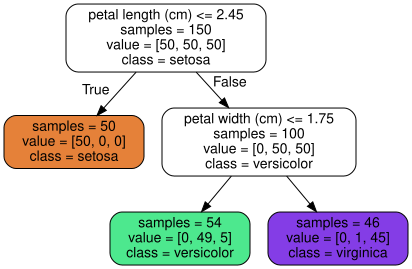

In [46]:
from graphviz import Source
from sklearn.tree import export_graphviz

export_graphviz(
    tree_clf,
    out_file="iris_tree.dot",
    feature_names=xnames,
    class_names=ynames,
    rounded=True,
    impurity=False,
    filled=True,
)

Source.from_file("iris_tree.dot")
#plt.savefig("plots/dtree_iris_depth2_tree_v2.pdf")

<Figure size 640x480 with 0 Axes>

/tmp/ipykernel_2216128/1749797985.py:27: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


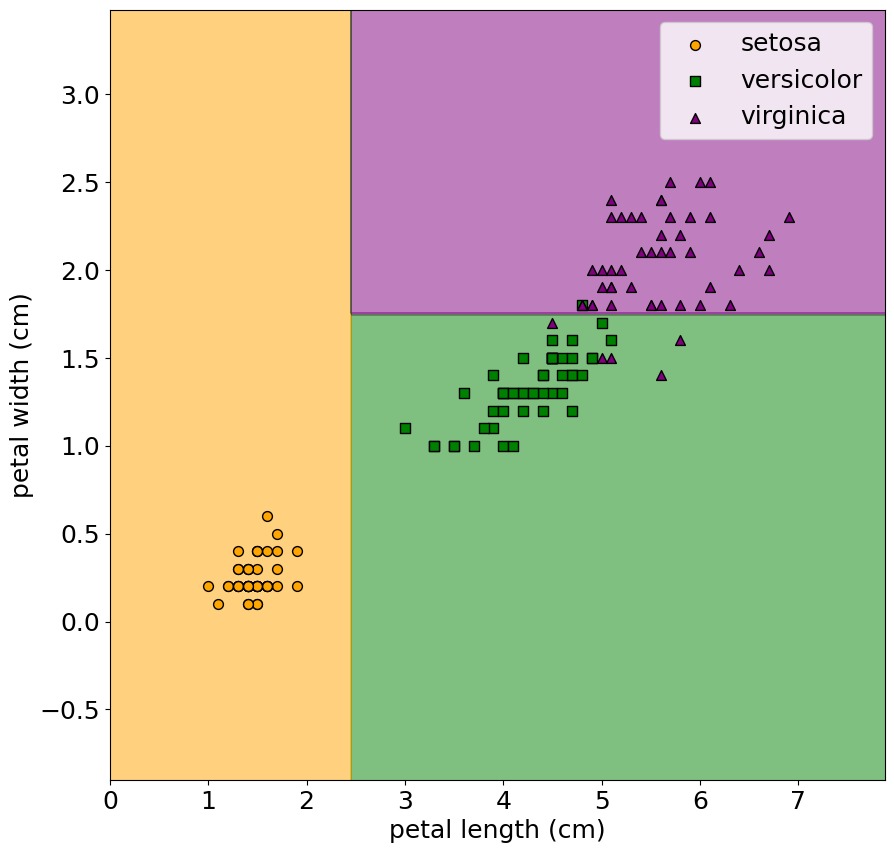

In [27]:
plot_surface(tree_clf, X, y, xnames, ynames)
plt.savefig("plots/dtree_iris_depth2_surface_v2.pdf")

# Depth 3

In [28]:
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


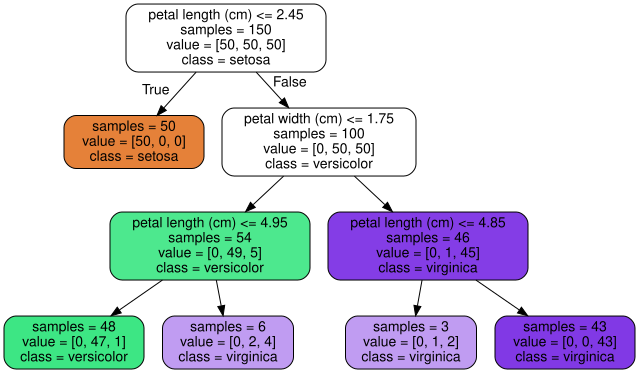

In [29]:
export_graphviz(
    tree_clf,
    out_file="iris_tree.dot",
    feature_names=xnames,
    class_names=ynames,
    rounded=True,
    impurity=False,
    filled=True,
)

Source.from_file("iris_tree.dot")

/tmp/ipykernel_2216128/1749797985.py:27: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


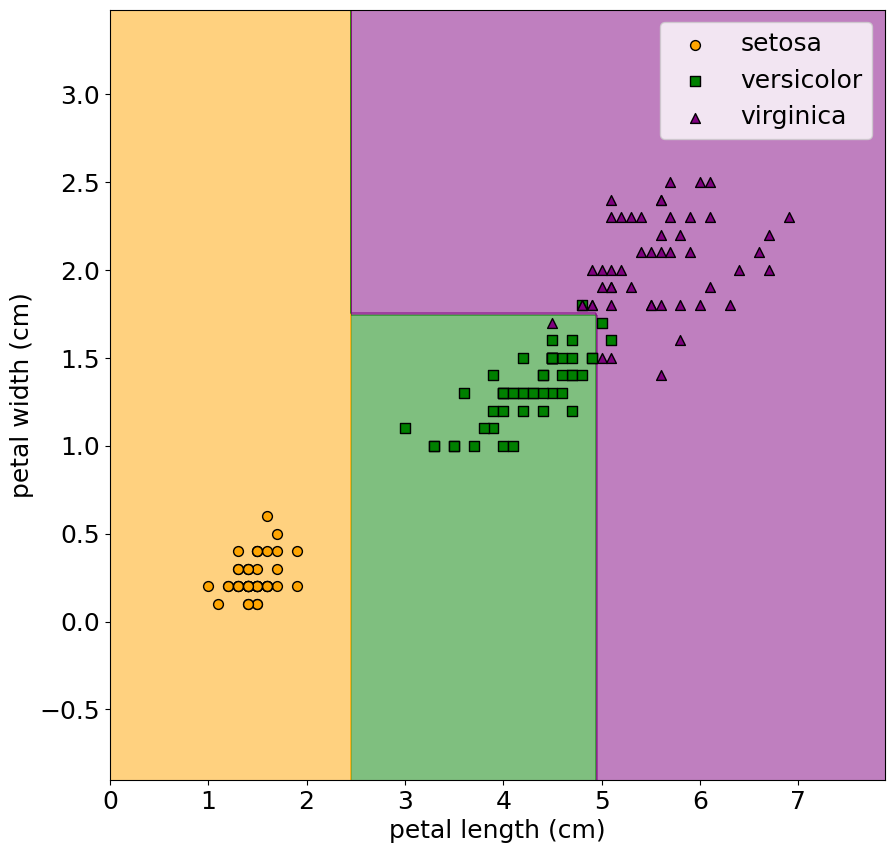

In [12]:
plot_surface(tree_clf, X, y, xnames, ynames)

# Depth unrestricted

In [13]:
tree_clf = DecisionTreeClassifier(max_depth=None, random_state=42)
tree_clf.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


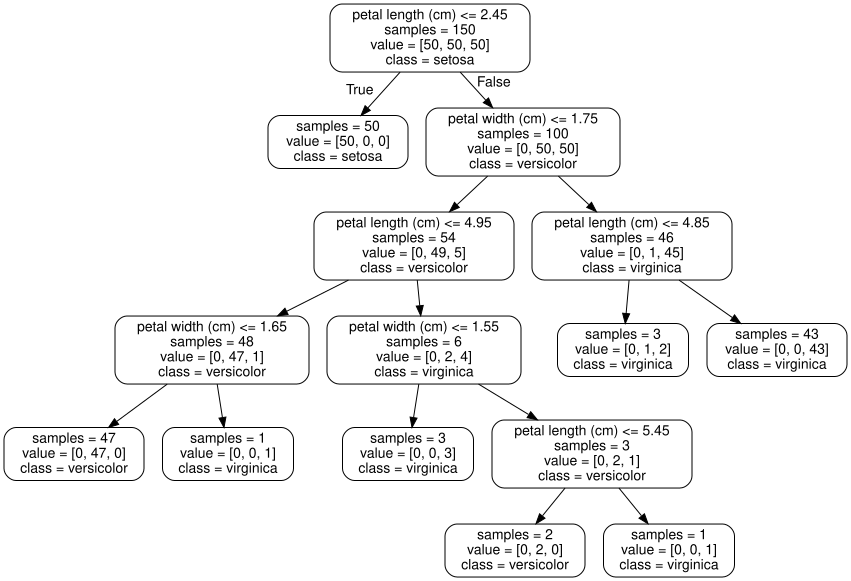

In [14]:
from graphviz import Source
from sklearn.tree import export_graphviz

export_graphviz(
    tree_clf,
    out_file="iris_tree.dot",
    feature_names=xnames,
    class_names=ynames,
    rounded=True,
    filled=False,
    impurity=False,
)

Source.from_file("iris_tree.dot")

/tmp/ipykernel_2216128/1749797985.py:27: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


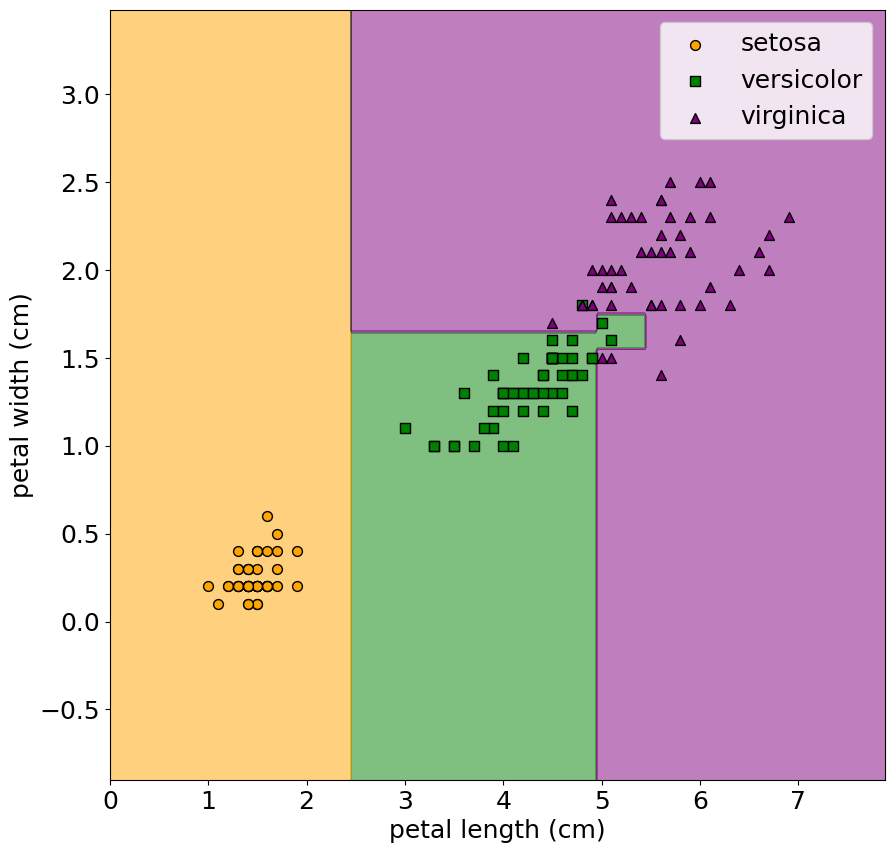

In [15]:
plot_surface(tree_clf, X, y, xnames, ynames)

# Visualization of the decision boundary for the Giny split
Généré avec l'aide de Gemini.

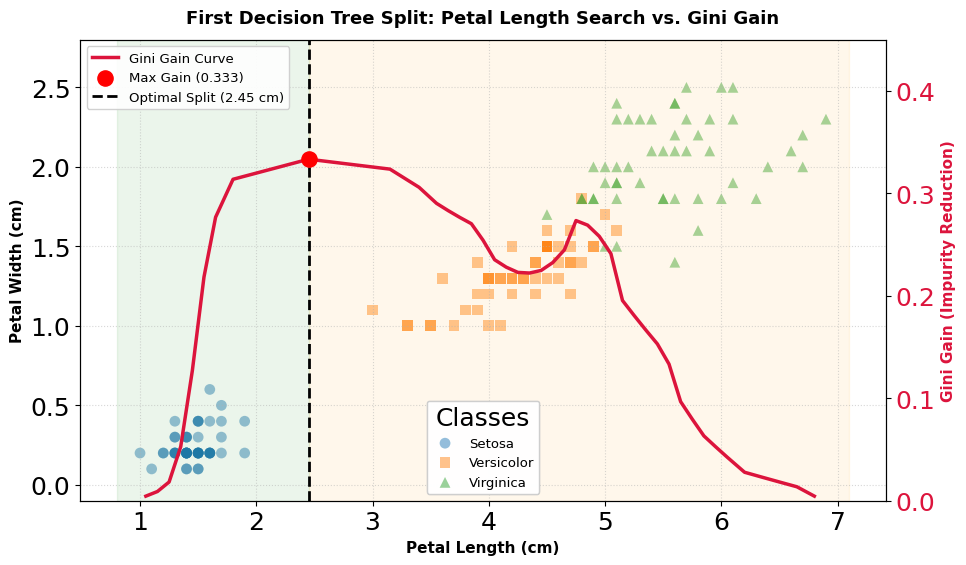

In [47]:
# ==============================================================================
# Visualizing the Decision Tree's First Split Criterion (Petal Length <= 2.45 cm)
# ==============================================================================

X = iris.data[:, [2, 3]]  # Feature 2: Petal length (cm), Feature 3: Petal width (cm)
y = iris.target
target_names = iris.target_names

x_petal = X[:, 0]
y_petal = X[:, 1]

# 2. Compute Gini Gain for candidate splits along Petal Length
def gini_impurity(y_subset):
    if len(y_subset) == 0:
        return 0.0
    _, counts = np.unique(y_subset, return_counts=True)
    probs = counts / len(y_subset)
    return 1.0 - np.sum(probs ** 2)

total_samples = len(y)
initial_gini = gini_impurity(y)

sorted_x = np.sort(np.unique(x_petal))
candidate_thresholds = (sorted_x[:-1] + sorted_x[1:]) / 2.0

gini_gains = []
for t in candidate_thresholds:
    left_mask = x_petal <= t
    y_left, y_right = y[left_mask], y[~left_mask]
    
    weighted_gini = (len(y_left) / total_samples) * gini_impurity(y_left) + \
                    (len(y_right) / total_samples) * gini_impurity(y_right)
    gini_gains.append(initial_gini - weighted_gini)

gini_gains = np.array(gini_gains)
best_idx = np.argmax(gini_gains)
best_threshold = candidate_thresholds[best_idx]
max_gain = gini_gains[best_idx]

# 3. Create Overlaid Plot
fig, ax1 = plt.subplots(figsize=(10, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

# --- Scatter Plot for Data Points ---
class_handles = []
for class_idx, class_name in enumerate(target_names):
    mask = y == class_idx
    handle = ax1.scatter(
        x_petal[mask], y_petal[mask], 
        c=colors[class_idx], marker=markers[class_idx],
        alpha=0.45, s=60, label=f'{class_name.capitalize()}', edgecolors='none'
    )
    class_handles.append(handle)

ax1.set_xlabel('Petal Length (cm)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Petal Width (cm)', fontsize=11, fontweight='bold')
ax1.set_ylim(-0.1, max(y_petal) + 0.3)

# Optimal split vertical line
split_line = ax1.axvline(
    best_threshold, color='black', linestyle='--', linewidth=2, 
    label=f'Optimal Split ({best_threshold:.2f} cm)'
)

# --- Secondary Y-Axis for Gini Gain Curve ---
ax2 = ax1.twinx()
gain_line, = ax2.plot(
    candidate_thresholds, gini_gains, 
    color='crimson', linewidth=2.5, label='Gini Gain Curve'
)
max_gain_pt = ax2.scatter(
    [best_threshold], [max_gain], 
    color='red', s=120, zorder=5, label=f'Max Gain ({max_gain:.3f})'
)

ax2.set_ylabel('Gini Gain (Impurity Reduction)', fontsize=11, fontweight='bold', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')
ax2.set_ylim(0, max(gini_gains) * 1.35)

# Highlight left and right regions created by the optimal split
ax1.axvspan(min(x_petal) - 0.2, best_threshold, color='green', alpha=0.08)#, label='Left Region (Setosa)')
ax1.axvspan(best_threshold, max(x_petal) + 0.2, color='orange', alpha=0.08)#, label='Right Region (Versicolor/Virginica)')

# --- Split Legends into Two Locations ---
# Top-Left Legend: Split criteria and curve
legend_lines = ax1.legend(
    handles=[gain_line, max_gain_pt, split_line], 
    loc='upper left', framealpha=0.9, fontsize=9.5
)
ax1.add_artist(legend_lines)

# Bottom-Right Legend: Class names
legend_classes = ax1.legend(
    handles=class_handles, 
    loc='lower center', title='Classes', framealpha=0.9, fontsize=9.5
)
ax1.add_artist(legend_classes)  # Re-add top legend after creating second legend

plt.title('First Decision Tree Split: Petal Length Search vs. Gini Gain', fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("plots/split_decision_visual.pdf")
plt.show()